<a href="https://colab.research.google.com/github/sarathi-14/Credit-Gaurd-ML-Task-1/blob/main/Zomato_Rating_Prediction_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Zomato Restaurant Reviews: Merge, Clean, and Predict Ratings

This Colab notebook combines restaurant metadata with customer reviews, prepares the data, and trains a model to predict a review's numeric rating from its text and restaurant information.

**Target:** `Rating` (numeric regression). Reviews with missing or nonnumeric ratings are excluded. The holdout split is grouped by restaurant so the evaluation checks performance on restaurants the model did not train on.

> In Colab, upload this notebook, then run each cell in order. When prompted, select both CSV files.

In [1]:
# Imports (scikit-learn, pandas, matplotlib, and seaborn are available in Colab)
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib


## 1. Upload and load the two datasets

In [4]:
uploaded = files.upload()

review_file = next((name for name in uploaded if 'review' in name.lower() and name.lower().endswith('.csv')), None)
metadata_file = next((name for name in uploaded if ('metadata' in name.lower() or 'names' in name.lower()) and name.lower().endswith('.csv')), None)
if review_file is None or metadata_file is None:
    raise ValueError('Please upload both the reviews CSV and the restaurant names/metadata CSV.')

reviews = pd.read_csv(review_file)
restaurants = pd.read_csv(metadata_file)
print('Reviews:', reviews.shape)
print('Restaurant metadata:', restaurants.shape)
display(reviews.head(3))
display(restaurants.head(3))


Saving Zomato Restaurant names and Metadata.csv to Zomato Restaurant names and Metadata (1).csv
Saving Zomato Restaurant reviews.csv to Zomato Restaurant reviews (1).csv
Reviews: (10000, 7)
Restaurant metadata: (105, 6)


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"


## 2. Standardize columns and merge

In [5]:
# Normalize column labels to avoid accidental whitespace mismatches.
reviews.columns = reviews.columns.str.strip()
restaurants.columns = restaurants.columns.str.strip()

required_reviews = {'Restaurant', 'Review', 'Rating'}
required_metadata = {'Name'}
if not required_reviews.issubset(reviews.columns):
    raise ValueError(f'Reviews file must contain {required_reviews}; found {set(reviews.columns)}')
if not required_metadata.issubset(restaurants.columns):
    raise ValueError(f'Metadata file must contain {required_metadata}; found {set(restaurants.columns)}')

# Deduplicate metadata by restaurant name before joining, to prevent row multiplication.
restaurants = restaurants.drop_duplicates(subset='Name', keep='first').copy()
merged = reviews.merge(restaurants, left_on='Restaurant', right_on='Name', how='left', indicator=True)
print('Merged shape:', merged.shape)
print('Metadata match status:')
print(merged['_merge'].value_counts())
print('Review restaurants without metadata:', merged.loc[merged['_merge'] == 'left_only', 'Restaurant'].nunique())
merged = merged.drop(columns=['Name', '_merge'], errors='ignore')
display(merged.head(3))


Merged shape: (10000, 14)
Metadata match status:
_merge
both          10000
left_only         0
right_only        0
Name: count, dtype: int64
Review restaurants without metadata: 0


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"


## 3. Clean and prepare fields

In [6]:
# Convert rating to numeric. The source includes blank values and a nonnumeric "Like" entry.
merged['Rating'] = pd.to_numeric(merged['Rating'], errors='coerce')
merged['Review'] = merged['Review'].fillna('').astype(str).str.strip()

# Remove rows without a valid target or usable review text, then remove exact duplicate records.
model_data = merged.dropna(subset=['Rating']).copy()
model_data = model_data[model_data['Review'].ne('')].copy()
rows_before_dedup = len(model_data)
model_data = model_data.drop_duplicates().reset_index(drop=True)
print(f'Rows retained: {len(model_data):,} (removed {len(merged) - rows_before_dedup:,} rows with invalid target/empty review; {rows_before_dedup - len(model_data):,} duplicates)')
print('Rating distribution:')
display(model_data['Rating'].value_counts().sort_index().rename('count').to_frame())

# Parse cost values such as "1,300" and picture count as numeric.
if 'Cost' in model_data.columns:
    model_data['Cost'] = pd.to_numeric(model_data['Cost'].astype(str).str.replace(',', '', regex=False), errors='coerce')
if 'Pictures' in model_data.columns:
    model_data['Pictures'] = pd.to_numeric(model_data['Pictures'], errors='coerce')

# Extract simple time features. Original timestamp is not used directly as text.
if 'Time' in model_data.columns:
    parsed_time = pd.to_datetime(model_data['Time'], errors='coerce')
    model_data['ReviewHour'] = parsed_time.dt.hour
    model_data['ReviewMonth'] = parsed_time.dt.month
    model_data['ReviewDayOfWeek'] = parsed_time.dt.dayofweek

# Report remaining missing values among commonly useful columns.
display(model_data.isna().sum().sort_values(ascending=False).head(12).rename('missing').to_frame())


Rows retained: 9,954 (removed 46 rows with invalid target/empty review; 0 duplicates)
Rating distribution:


,count
Rating,
1.0,1735
1.5,9
2.0,684
2.5,19
3.0,1192
3.5,47
4.0,2373
4.5,69
5.0,3826


,missing
Collections,4992
Timings,100
Restaurant,0
Rating,0
Metadata,0
Reviewer,0
Review,0
Pictures,0
Time,0
Cost,0


## 4. Choose predictors and split by restaurant

In [7]:
# Text is the review itself; restaurant details add context. Reviewer identity is excluded.
text_column = 'Review'
categorical_candidates = ['Restaurant', 'Cuisines', 'Collections', 'Timings']
numeric_candidates = ['Cost', 'Pictures', 'ReviewHour', 'ReviewMonth', 'ReviewDayOfWeek']
categorical_columns = [c for c in categorical_candidates if c in model_data.columns]
numeric_columns = [c for c in numeric_candidates if c in model_data.columns]

X = model_data[[text_column] + categorical_columns + numeric_columns].copy()
y = model_data['Rating'].astype(float)
groups = model_data['Restaurant'].astype(str)

# Grouped split gives a more realistic check for restaurants not seen during training.
if groups.nunique() >= 2:
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
    train_idx, test_idx = next(splitter.split(X, y, groups=groups))
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    print('Using a restaurant-grouped 80/20 holdout split.')
else:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
    print('Only one restaurant found; using a random 80/20 split.')
print('Train rows:', len(X_train), '| Test rows:', len(X_test))
print('Train restaurants:', groups.iloc[train_idx].nunique() if groups.nunique() >= 2 else groups.nunique(), '| Test restaurants:', groups.iloc[test_idx].nunique() if groups.nunique() >= 2 else groups.nunique())


Using a restaurant-grouped 80/20 holdout split.
Train rows: 7954 | Test rows: 2000
Train restaurants: 80 | Test restaurants: 20


## 5. Build and train a regression pipeline

In [8]:
text_transformer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    stop_words='english',
    sublinear_tf=True
)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler(with_mean=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('review_text', text_transformer, text_column),
    ('categories', categorical_transformer, categorical_columns),
    ('numbers', numeric_transformer, numeric_columns)
])
model = Pipeline(steps=[
    ('features', preprocessor),
    ('regressor', Ridge(alpha=2.0, solver='lsqr'))
])
model.fit(X_train, y_train)
print('Model trained.')


Model trained.


## 6. Evaluate the model

MAE:  0.705 rating points
RMSE: 0.900 rating points
R²:   0.626
Baseline MAE (always predict training median): 1.187


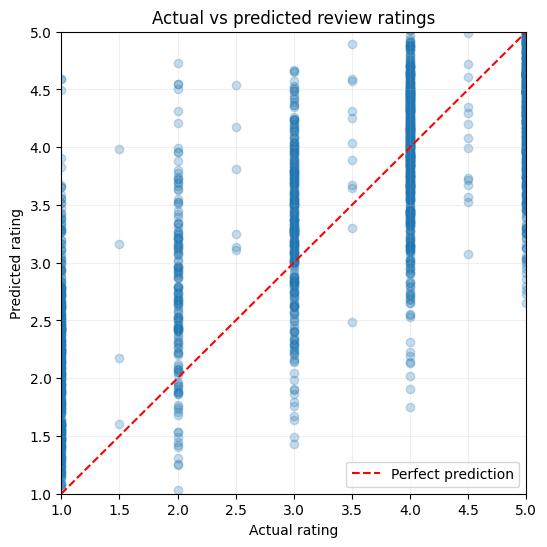

In [9]:
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)
print(f'MAE:  {mae:.3f} rating points')
print(f'RMSE: {rmse:.3f} rating points')
print(f'R²:   {r2:.3f}')
print('Baseline MAE (always predict training median):', f'{mean_absolute_error(y_test, np.repeat(y_train.median(), len(y_test))):.3f}')

plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.25)
plt.plot([1, 5], [1, 5], color='red', linestyle='--', label='Perfect prediction')
plt.xlim(1, 5)
plt.ylim(1, 5)
plt.xlabel('Actual rating')
plt.ylabel('Predicted rating')
plt.title('Actual vs predicted review ratings')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


### How to read the scores

- **MAE** is the average absolute rating error in rating points; lower is better.
- **RMSE** penalizes larger errors more heavily; lower is better.
- **R²** compares the model with predicting the average rating; values closer to 1 indicate a better fit.
- The baseline comparison helps show whether the model improves on a simple constant prediction.

The grouped holdout is intentionally demanding: test reviews come from restaurants excluded from training. Results may differ from a random review split.

## 7. Inspect example predictions

In [ ]:
results = X_test[[text_column] + categorical_columns].copy()
results['ActualRating'] = y_test.values
results['PredictedRating'] = np.round(predictions, 2)
results['AbsoluteError'] = np.round(np.abs(results['ActualRating'] - results['PredictedRating']), 2)
display(results.sort_values('AbsoluteError', ascending=False).head(10))


## 8. Save outputs

In [ ]:
# Save the cleaned merged data and trained pipeline to the Colab session.
cleaned_output = 'zomato_merged_cleaned.csv'
model_output = 'zomato_rating_model.joblib'
model_data.to_csv(cleaned_output, index=False)
joblib.dump(model, model_output)
print('Saved:', cleaned_output, 'and', model_output)

# Uncomment these lines to download both files to your computer.
# files.download(cleaned_output)
# files.download(model_output)


## Notes and next steps

- This model predicts **review ratings**, not restaurant popularity or future business performance.
- The source includes roughly 100 reviews per restaurant. The restaurant-grouped holdout is useful for estimating performance on unseen restaurants; for predicting new reviews at already-known restaurants, a random split may give a different score.
- Review text is the strongest expected signal and may not be available before a review is written. For a restaurant-level forecast without review text, remove `Review` from the predictors and define a different prediction target (for example, future average rating).
- The model's outputs are continuous. If desired, round and clip predictions to the source rating scale for display, while keeping the unrounded values for evaluation.